In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('credit_risk_dataset.csv')

In [3]:
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


# EDA

In [4]:
df.shape

(32581, 12)

In [5]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

In [6]:
df.dtypes

person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


In [8]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [9]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [10]:
df['person_emp_length']=df['person_emp_length'].fillna(df['person_emp_length'].mean())

In [11]:
df['loan_int_rate']=df['loan_int_rate'].fillna(df['loan_int_rate'].mean())

In [12]:
df.isnull().sum()

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(165)

In [14]:
df.drop_duplicates(inplace=True)

In [15]:
df.shape

(32416, 12)

In [16]:
df['person_age'].value_counts()

person_age
23     3861
22     3607
24     3526
25     3023
26     2462
27     2127
28     1848
29     1682
30     1310
21     1213
31     1139
32      961
33      855
34      708
35      619
36      547
37      478
38      373
39      301
40      270
41      241
42      187
43      163
44      141
45      108
46       94
47       94
48       75
50       52
49       48
51       39
52       36
53       30
54       24
55       20
58       19
20       15
57       15
60       15
56       15
65        9
66        9
61        9
62        7
64        7
70        7
59        5
69        5
144       3
73        3
63        3
123       2
78        1
94        1
80        1
84        1
76        1
67        1
Name: count, dtype: int64

In [17]:
df['person_income'].value_counts()

person_income
60000      1040
30000       844
50000       772
40000       655
45000       586
           ... 
115900        1
39240         1
720000        1
1900000       1
4888          1
Name: count, Length: 4295, dtype: int64

In [18]:
df['person_emp_length'].value_counts()

person_emp_length
0.000000      4086
2.000000      3832
3.000000      3442
5.000000      2926
1.000000      2897
4.000000      2863
6.000000      2652
7.000000      2186
8.000000      1676
9.000000      1359
4.789686       887
11.000000      735
10.000000      692
12.000000      571
13.000000      426
14.000000      334
15.000000      238
16.000000      165
17.000000      128
18.000000      104
19.000000       64
20.000000       42
21.000000       38
22.000000       19
24.000000       10
23.000000       10
25.000000        8
26.000000        6
27.000000        5
31.000000        4
28.000000        3
123.000000       2
30.000000        2
41.000000        1
34.000000        1
29.000000        1
38.000000        1
Name: count, dtype: int64

In [19]:
df['person_emp_length']=df['person_emp_length'].replace(123,df['person_emp_length'].mean())

In [20]:
df['person_emp_length'].value_counts()

person_emp_length
0.000000     4086
2.000000     3832
3.000000     3442
5.000000     2926
1.000000     2897
4.000000     2863
6.000000     2652
7.000000     2186
8.000000     1676
9.000000     1359
4.789686      887
11.000000     735
10.000000     692
12.000000     571
13.000000     426
14.000000     334
15.000000     238
16.000000     165
17.000000     128
18.000000     104
19.000000      64
20.000000      42
21.000000      38
22.000000      19
24.000000      10
23.000000      10
25.000000       8
26.000000       6
27.000000       5
31.000000       4
28.000000       3
4.790488        2
30.000000       2
41.000000       1
34.000000       1
29.000000       1
38.000000       1
Name: count, dtype: int64

In [21]:
df['cb_person_cred_hist_length'].value_counts()

cb_person_cred_hist_length
2     5925
3     5905
4     5881
7     1898
8     1893
9     1888
5     1875
6     1849
10    1846
14     492
12     483
11     462
16     449
13     443
15     437
17     406
20      31
24      30
28      27
27      22
22      22
23      22
30      22
19      21
21      20
18      19
25      18
26      16
29      14
Name: count, dtype: int64

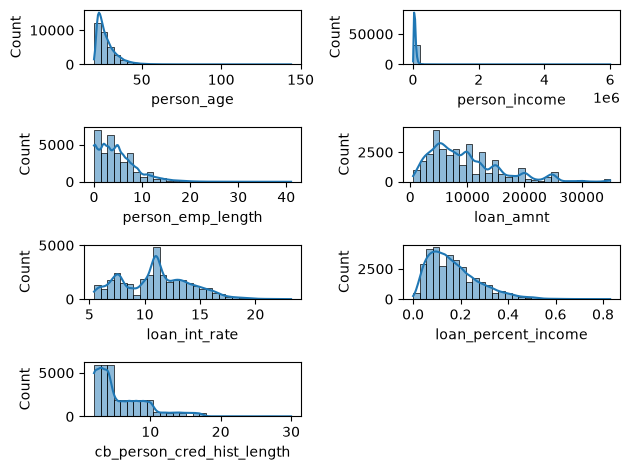

In [22]:
cols=['person_age', 'person_income','person_emp_length', 'loan_amnt','loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

def plotting(var,num):
    plt.subplot(4,2,num)
    sns.histplot(df[var],kde=True,bins=30)

for index,col in enumerate(cols,start=1):
    plotting(col,index)

plt.tight_layout()    

<Axes: >

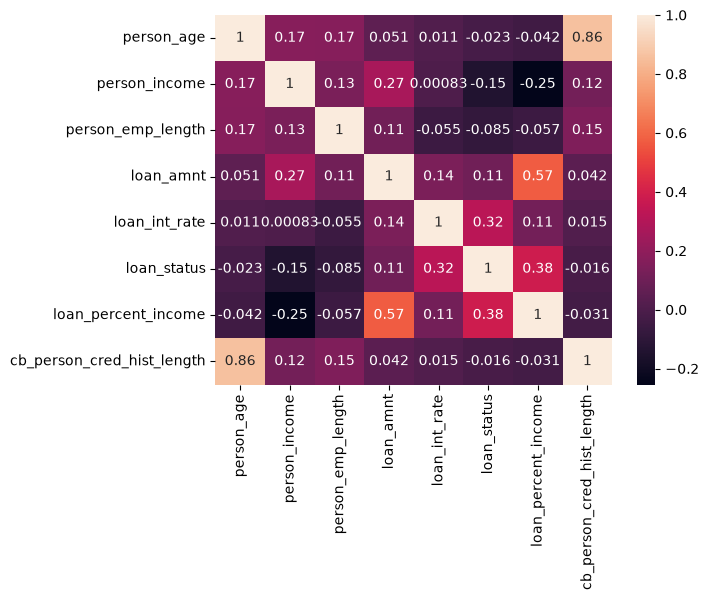

In [23]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

# Data Preprocessing and Data Cleaning

In [24]:
df['cb_person_default_on_file']=df['cb_person_default_on_file'].map({"Y":1,"N":0})

In [25]:
df_one_hot_encode=pd.get_dummies(df,columns=['person_home_ownership','loan_intent', 'loan_grade'],drop_first=False)

In [26]:
df_one_hot_encode

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,...,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_A,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G
0,22,59000,4.790488,35000,16.02,1,0.59,1,3,False,...,False,True,False,False,False,False,True,False,False,False
1,21,9600,5.000000,1000,11.14,0,0.10,0,2,False,...,False,False,False,False,True,False,False,False,False,False
2,25,9600,1.000000,5500,12.87,1,0.57,0,3,True,...,True,False,False,False,False,True,False,False,False,False
3,23,65500,4.000000,35000,15.23,1,0.53,0,2,False,...,True,False,False,False,False,True,False,False,False,False
4,24,54400,8.000000,35000,14.27,1,0.55,1,4,False,...,True,False,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,1.000000,5800,13.16,0,0.11,0,30,True,...,False,True,False,False,False,True,False,False,False,False
32577,54,120000,4.000000,17625,7.49,0,0.15,0,19,True,...,False,True,False,True,False,False,False,False,False,False
32578,65,76000,3.000000,35000,10.99,1,0.46,0,28,False,...,False,False,False,False,True,False,False,False,False,False
32579,56,150000,5.000000,15000,11.48,0,0.10,0,26,True,...,False,True,False,False,True,False,False,False,False,False


In [27]:
exclude_cols = ['person_age', 'person_income','person_emp_length', 'loan_amnt','loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
cols_to_convert = df_one_hot_encode.columns.drop(exclude_cols)
df_one_hot_encode[cols_to_convert] = df_one_hot_encode[cols_to_convert].astype(int)

In [28]:
df_one_hot_encode

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,...,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_A,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G
0,22,59000,4.790488,35000,16.02,1,0.59,1,3,0,...,0,1,0,0,0,0,1,0,0,0
1,21,9600,5.000000,1000,11.14,0,0.10,0,2,0,...,0,0,0,0,1,0,0,0,0,0
2,25,9600,1.000000,5500,12.87,1,0.57,0,3,1,...,1,0,0,0,0,1,0,0,0,0
3,23,65500,4.000000,35000,15.23,1,0.53,0,2,0,...,1,0,0,0,0,1,0,0,0,0
4,24,54400,8.000000,35000,14.27,1,0.55,1,4,0,...,1,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,1.000000,5800,13.16,0,0.11,0,30,1,...,0,1,0,0,0,1,0,0,0,0
32577,54,120000,4.000000,17625,7.49,0,0.15,0,19,1,...,0,1,0,1,0,0,0,0,0,0
32578,65,76000,3.000000,35000,10.99,1,0.46,0,28,0,...,0,0,0,0,1,0,0,0,0,0
32579,56,150000,5.000000,15000,11.48,0,0.10,0,26,1,...,0,1,0,0,1,0,0,0,0,0


In [29]:
from sklearn.preprocessing import StandardScaler
numeric_cols=['person_age', 'person_income',
       'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
scaler=StandardScaler()
df_one_hot_encode[numeric_cols]=scaler.fit_transform(df_one_hot_encode[numeric_cols])

In [30]:
df_one_hot_encode

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,...,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_A,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G
0,-0.904471,-0.114354,0.001832,4.018287,1.622860,1,3.929865,1,-0.692614,0,...,0,1,0,0,0,0,1,0,0,0
1,-1.061852,-0.910941,0.054454,-1.359219,0.039983,0,-0.657707,0,-0.938982,0,...,0,0,0,0,1,0,0,0,0,0
2,-0.432327,-0.910941,-0.950200,-0.647491,0.601126,1,3.742617,0,-0.692614,1,...,1,0,0,0,0,1,0,0,0,0
3,-0.747089,-0.009540,-0.196710,4.018287,1.366616,1,3.368121,0,-0.938982,0,...,1,0,0,0,0,1,0,0,0,0
4,-0.589708,-0.188530,0.807944,4.018287,1.055230,1,3.555369,1,-0.446246,0,...,1,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32576,4.603869,-0.211106,-0.950200,-0.600042,0.695190,0,-0.564083,0,5.959324,1,...,0,1,0,0,0,1,0,0,0,0
32577,4.131726,0.869285,-0.196710,1.270223,-1.143932,0,-0.189587,0,3.249275,1,...,0,1,0,1,0,0,0,0,0,0
32578,5.862918,0.159775,-0.447873,4.018287,-0.008671,1,2.712754,0,5.466588,0,...,0,0,0,0,1,0,0,0,0,0
32579,4.446488,1.353041,0.054454,0.855048,0.150265,0,-0.657707,0,4.973852,1,...,0,1,0,0,1,0,0,0,0,0


In [31]:
df_one_hot_encode.shape

(32416, 26)

In [32]:
df_one_hot_encode.columns

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length',
       'person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER',
       'person_home_ownership_OWN', 'person_home_ownership_RENT',
       'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION',
       'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL',
       'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'loan_grade_A',
       'loan_grade_B', 'loan_grade_C', 'loan_grade_D', 'loan_grade_E',
       'loan_grade_F', 'loan_grade_G'],
      dtype='str')

Feature Engineering and Feature Selection

In [33]:
from scipy.stats import chi2_contingency

# Set significance level
alpha = 0.05

# 1. Define your target and numeric features to exclude from the Chi-Square test
target_col = "loan_status"
numeric_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

# Identify the categorical/one-hot encoded columns to test
columns_to_test = [
    col
    for col in df_one_hot_encode.columns
    if col not in [target_col] + numeric_features
]

# Run Chi-Square test for each feature column individually
chi2_results = {}
cols_to_keep = []

for col in columns_to_test:
    # Generate contingency table directly with loan_status
    contingency = pd.crosstab(df_one_hot_encode[col], df_one_hot_encode[target_col])

    # Run the Chi-Square test
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)

    # Check significance
    if p_val < alpha:
        decision = "Reject Null (Keep Feature)"
        cols_to_keep.append(col)
    else:
        decision = "Fail to Reject Null (Drop Feature)"

    chi2_results[col] = {
        "chi2_statistic": chi2_stat,
        "p_value": p_val,
        "Decision": decision,
    }

# Convert results summary to a DataFrame for review
chi2_df = pd.DataFrame(chi2_results).T.sort_values(by="p_value")

# 2. Create the final filtered DataFrame
# Includes selected significant categorical columns, original numeric features, and the target
final_cols = cols_to_keep + numeric_features + [target_col]
df_final = df_one_hot_encode[final_cols].copy()

# Print execution summary
print(f"Original Columns: {df_one_hot_encode.shape[1]}")
print(
    f"Dropped {len(columns_to_test) - len(cols_to_keep)} insignificant categorical columns."
)
print(f"Final Data Shape: {df_final.shape}\n")

# Display the test results breakdown
chi2_df[["chi2_statistic", "p_value", "Decision"]]

Original Columns: 26
Dropped 0 insignificant categorical columns.
Final Data Shape: (32416, 26)



,chi2_statistic,p_value,Decision
person_home_ownership_RENT,1837.060431,0.0,Reject Null (Keep Feature)
loan_grade_D,3296.560568,0.0,Reject Null (Keep Feature)
loan_grade_A,1325.273347,0.0,Reject Null (Keep Feature)
person_home_ownership_MORTGAGE,1138.471352,0.0,Reject Null (Keep Feature)
loan_grade_E,1052.406994,0.0,Reject Null (Keep Feature)
cb_person_default_on_file,1041.973789,0.0,Reject Null (Keep Feature)
person_home_ownership_OWN,335.787212,0.0,Reject Null (Keep Feature)
loan_grade_F,333.757298,0.0,Reject Null (Keep Feature)
loan_grade_B,275.101406,0.0,Reject Null (Keep Feature)
loan_grade_G,215.567174,0.0,Reject Null (Keep Feature)


In [34]:
df_final.shape

(32416, 26)

In [35]:
df_final.columns

Index(['cb_person_default_on_file', 'person_home_ownership_MORTGAGE',
       'person_home_ownership_OTHER', 'person_home_ownership_OWN',
       'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION',
       'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT',
       'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE',
       'loan_grade_A', 'loan_grade_B', 'loan_grade_C', 'loan_grade_D',
       'loan_grade_E', 'loan_grade_F', 'loan_grade_G', 'person_age',
       'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate',
       'loan_percent_income', 'cb_person_cred_hist_length', 'loan_status'],
      dtype='str')

In [36]:
df_final.head()

,cb_person_default_on_file,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,...,loan_grade_F,loan_grade_G,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status
0,1,0,0,0,1,0,0,0,0,1,...,0,0,-0.904471,-0.114354,0.001832,4.018287,1.622860,3.929865,-0.692614,1
1,0,0,0,1,0,0,1,0,0,0,...,0,0,-1.061852,-0.910941,0.054454,-1.359219,0.039983,-0.657707,-0.938982,0
2,0,1,0,0,0,0,0,0,1,0,...,0,0,-0.432327,-0.910941,-0.950200,-0.647491,0.601126,3.742617,-0.692614,1
3,0,0,0,0,1,0,0,0,1,0,...,0,0,-0.747089,-0.009540,-0.196710,4.018287,1.366616,3.368121,-0.938982,1
4,1,0,0,0,1,0,0,0,1,0,...,0,0,-0.589708,-0.188530,0.807944,4.018287,1.055230,3.555369,-0.446246,1


In [37]:
X=df_final.drop("loan_status",axis=1)
y=df_final["loan_status"]

# Model Training and Model Evaluation

### Logistic Regression

In [38]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [39]:
from sklearn.linear_model import LogisticRegression
model_logistic_regression=LogisticRegression()
model_logistic_regression.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [40]:
y_pred_logistic_regression=model_logistic_regression.predict(X_test)

In [41]:
y_pred_logistic_regression

array([0, 1, 0, ..., 0, 0, 0], shape=(10698,))

In [42]:
y_test

20562    0
1090     1
4762     0
12381    0
15112    0
        ..
9198     0
23988    0
16642    0
22886    1
23262    0
Name: loan_status, Length: 10698, dtype: int64

In [43]:
from sklearn.metrics import accuracy_score, confusion_matrix , classification_report

In [44]:
accuracy_score(y_test,y_pred_logistic_regression)

0.8653954010095345

In [45]:
confusion_matrix(y_test,y_pred_logistic_regression)

array([[7954,  391],
       [1049, 1304]])

In [46]:
print(classification_report(y_test,y_pred_logistic_regression))

              precision    recall  f1-score   support

           0       0.88      0.95      0.92      8345
           1       0.77      0.55      0.64      2353

    accuracy                           0.87     10698
   macro avg       0.83      0.75      0.78     10698
weighted avg       0.86      0.87      0.86     10698



### KNN

In [47]:
from sklearn.neighbors import KNeighborsClassifier
model_KNN = KNeighborsClassifier(n_neighbors=5)
model_KNN.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [48]:
y_pred_KNN=model_KNN.predict(X_test)

In [49]:
y_pred_KNN

array([0, 1, 0, ..., 0, 0, 0], shape=(10698,))

In [50]:
y_test

20562    0
1090     1
4762     0
12381    0
15112    0
        ..
9198     0
23988    0
16642    0
22886    1
23262    0
Name: loan_status, Length: 10698, dtype: int64

In [51]:
accuracy_score(y_test,y_pred_KNN)

0.8899794354084876

In [52]:
confusion_matrix(y_test,y_pred_KNN)

array([[8096,  249],
       [ 928, 1425]])

In [53]:
print(classification_report(y_test,y_pred_KNN))

              precision    recall  f1-score   support

           0       0.90      0.97      0.93      8345
           1       0.85      0.61      0.71      2353

    accuracy                           0.89     10698
   macro avg       0.87      0.79      0.82     10698
weighted avg       0.89      0.89      0.88     10698



### Naive Bayes

In [54]:
from sklearn.naive_bayes import GaussianNB
model_NB = GaussianNB()
model_NB.fit(X_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[16982., 4736.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.78,0.22]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.093e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](25,)","['cb_person_default_on_file','person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER',...,'loan_int_rate','loan_percent_income', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,25
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 25)","[[ 0.14, 0.46, 0. ,...,-0.17,-0.2 , 0.01], [ 0.3 , 0.24, 0. ,..., 0.6 , 0.74,-0.03]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 25)","[[0.12,0.25,0. ,...,0.84,0.67,0.98], [0.21,0.18,0. ,...,1.07,1.52,1.01]]"


In [55]:
y_pred_NB=model_NB.predict(X_test)

In [56]:
y_pred_NB

array([0, 1, 0, ..., 0, 0, 0], shape=(10698,))

In [57]:
y_test

20562    0
1090     1
4762     0
12381    0
15112    0
        ..
9198     0
23988    0
16642    0
22886    1
23262    0
Name: loan_status, Length: 10698, dtype: int64

In [58]:
accuracy_score(y_test,y_pred_NB)

0.8388483828753038

In [59]:
confusion_matrix(y_test,y_pred_NB)

array([[7888,  457],
       [1267, 1086]])

In [60]:
print(classification_report(y_test,y_pred_NB))

              precision    recall  f1-score   support

           0       0.86      0.95      0.90      8345
           1       0.70      0.46      0.56      2353

    accuracy                           0.84     10698
   macro avg       0.78      0.70      0.73     10698
weighted avg       0.83      0.84      0.83     10698



### Decision Tree

In [61]:
from sklearn.tree import DecisionTreeClassifier
model_DT = DecisionTreeClassifier(random_state=42)
model_DT.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [62]:
y_pred_DT=model_DT.predict(X_test)

In [63]:
y_pred_DT

array([0, 1, 0, ..., 1, 1, 0], shape=(10698,))

In [64]:
y_test

20562    0
1090     1
4762     0
12381    0
15112    0
        ..
9198     0
23988    0
16642    0
22886    1
23262    0
Name: loan_status, Length: 10698, dtype: int64

In [65]:
accuracy_score(y_test,y_pred_DT)

0.8868947466816227

In [66]:
confusion_matrix(y_test,y_pred_DT)

array([[7687,  658],
       [ 552, 1801]])

In [67]:
print(classification_report(y_test,y_pred_DT))

              precision    recall  f1-score   support

           0       0.93      0.92      0.93      8345
           1       0.73      0.77      0.75      2353

    accuracy                           0.89     10698
   macro avg       0.83      0.84      0.84     10698
weighted avg       0.89      0.89      0.89     10698

